# 阅读与运行指南

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

你把同一个苹果放到秤上，先后看到 150 克、152 克、149 克。苹果没有变，读数却在变。你会用哪个数代表它的重量？如果要根据几次位置读数猜一辆小车的速度，又该怎么办？

这本书从这些问题出发。**最小二乘，就是先规定怎样给误差打分，再找出总分最低的那组设置。**“二乘”是平方的旧说法，例如 $3^2=3\times3=9$。它不是一种能自动找出真相的魔法，而是一套把猜测、测量和检查连接起来的办法。

不需要先学完大学数学。你可以先会加减乘除、读简单折线图，边运行例子边补知识。不过，运行代码仍需要一点 Python 基础：变量是给数起名字，数组是一排数，函数是可反复使用的计算步骤。如果这些也陌生，先看 [零起点阅读指南](../docs/reading-guide.md)，再回到这里。学历不是门槛；需要补的是具体知识。

## 怎样读，才不会一上来就被公式拦住

第一次阅读，先读每章的生活问题、操作提示和读图说明。标着“想知道公式怎么来”的部分可以暂时跳过；它们保留了推导，方便以后查。**会解释现象，比会背算法名字更早一步，也更重要。**

建议先读第01、02章：会算平均、会拟合直线、会说清误差是什么。再读第05、06章：比较可靠与不可靠的测量，看看曲线为什么会“记住错题”。第03、04章补上矩阵和可靠计算；第07—11章解释电脑怎样一步步调整。第12—15章把前面的办法连成完整任务。附录A和[白话词典](../docs/plain-language-glossary.md)随用随查，附录C留到进阶时再读。

本书参考 Roger Labbe 的 *Kalman and Bayesian Filters in Python* 的教学思路：从读者能想象的问题出发，让文字、实验和结果互相解释。这里的故事和讲解按最小二乘问题原创组织，并非对其正文的翻译。非线性理论的主要参考资料见附录D。

## 先认识四个会反复出现的词

- **观测**：实际读到的数，例如秤显示的 152 克。
- **模型**：我们暂时采用的解释，例如“苹果的重量一直没变”。
- **参数**：模型中还要决定的数，例如猜测的苹果重量。
- **残差**：模型算出的数减去实际读数。猜 151、读到 152，残差就是 $-1$；负号表示猜低了。

把所有残差各自平方，再相加，就是本书的基本评分。为了后面求导方便，再乘 $1/2$；所有候选的分数一起减半，冠军不会变。写成公式是

$$r_i(x)=f_i(x)-y_i,\qquad F(x)=\frac12\sum_{i=1}^m r_i(x)^2=\frac12\|r(x)\|_2^2.$$

这里 $x$ 是待调的设置，$y_i$ 是第 $i$ 次读数，$f_i(x)$ 是模型对这次读数的预测，$m$ 是读数个数。$\sum$ 表示“逐个相加”；$\|r\|_2^2$ 只是“这一排误差的平方和”的简写，先不必背它。

本书始终用“模型减观测”。换成“观测减模型”也能得到相同平方分数，但计算变化率的代码也要一起换符号，不能只改一半。

## 先把工具准备好

下面是公共准备代码，每章都有一份。它负责找到本书目录、载入计算与画图工具、设置图的大小。第一次可以先运行，不用逐行弄懂。运行后没有新图或打印文字，通常是正常的。

所有例子使用本地数据或程序生成的数据；依赖安装完成后，章节计算无需联网。

In [2]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

## 第一次运行：让电脑找回一条直线

下面先造出五个点：时间是 0、1、2、3、4，对应数值是 1、3、5、7、9。规律是“从 1 开始，每过一个时间单位增加 2”。我们假装不知道这两个数，让电脑从点中找回来。

在 Jupyter 中，点选代码框，按 **Shift+Enter** 运行并进入下一格。正常应看到 `intercept, slope: [1. 2.]`：`intercept` 是起始值，`slope` 是每单位时间增加多少。图中的圆点叫 `data`，表示数据；直线叫 `fit`，表示拟合结果。两者重合，因为这次故意没有加入测量误差。

先猜一猜：若每次增加 3，会找出什么？然后把 `y = 1 + 2*t` 改成 `y = 1 + 3*t`，**并把紧随其后的断言预期 `[1, 2]` 改成 `[1, 3]`**，再运行。`assert` 是作者放的自检，不是算法；只改造数规则而不改预期，出现 `AssertionError` 正是在提醒两者不一致。试完可以恢复原值。

intercept, slope: [1. 2.] rank: 2


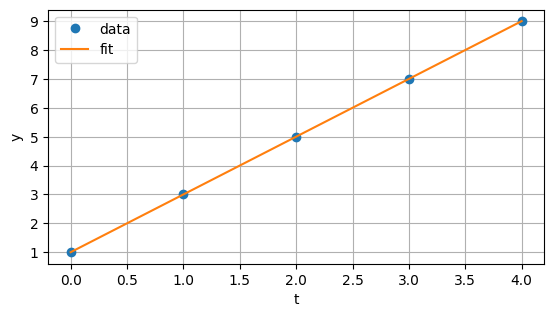

In [3]:
t = np.arange(5., dtype=float)
A = np.column_stack([np.ones_like(t), t])
y = 1 + 2*t
x, _, rank, singular = np.linalg.lstsq(A, y, rcond=None)
print('intercept, slope:', x, 'rank:', rank)
assert np.allclose(x, [1, 2])
plt.plot(t, y, 'o', label='data')
plt.plot(t, A@x, label='fit')
plt.xlabel('t'); plt.ylabel('y'); plt.legend(); plt.show()

## 怎样确认自己在理解，而不只是按运行键

你能说出“我在调哪几个数、程序按什么给误差打分、图上的点和线各是什么”，就已经完成了第一步。以后再逐渐补上：单位是否一致、剩下的误差有没有规律、数据是否足以分清这些参数、程序为什么停下。

例如，把上面的时间全部改为零，相当于只在起跑瞬间拍五张照片。照片再多，也看不出车跑得多快。数学上叫“秩亏”：数据没有提供足够的独立信息。程序可能仍返回一个斜率，但这个数不是被数据测出来的。想动手时先注释掉原来的断言，因为它只适用于原实验。

## 安装和遇到问题时怎么办

需要 Python 3.11 或更新版本，推荐 3.12。按仓库 README 的步骤建虚拟环境，安装 `requirements.txt` 和 JupyterLab，然后在项目目录运行 `python -m jupyterlab`，打开 `notebooks/00-guide.ipynb`。不要只运行中间一格：出现 `NameError` 时先从本章第一格重新运行；出现 `ModuleNotFoundError` 时先核对所选 Python 环境和依赖安装。

开发时用 `python -m unittest discover -s tests -v` 检查现有代码。`python tools/build.py --execute --test` 会执行全部章节并重写 Notebook 的保存输出；自己的实验副本更适合反复修改。中文 PDF 构建另需 Pandoc 和带中文组件的 TeX Live，完整命令见 README。这是制作书籍的工具，不是读懂第一章的前提。

## 先停一下，自己说一遍

问题：为什么不能先把正负误差加起来，再比较总数？

提示：一个猜高 2，一个猜低 2。

解答：直接相加会得到零，好像完全没错；各自平方后是 $4+4=8$，两次偏差都被记住了。平方只是本书先采用的一种评分规则，第12章会看到它也有不足。